✅ Entrenamiento del Mapa de Kohonen finalizado con éxito.


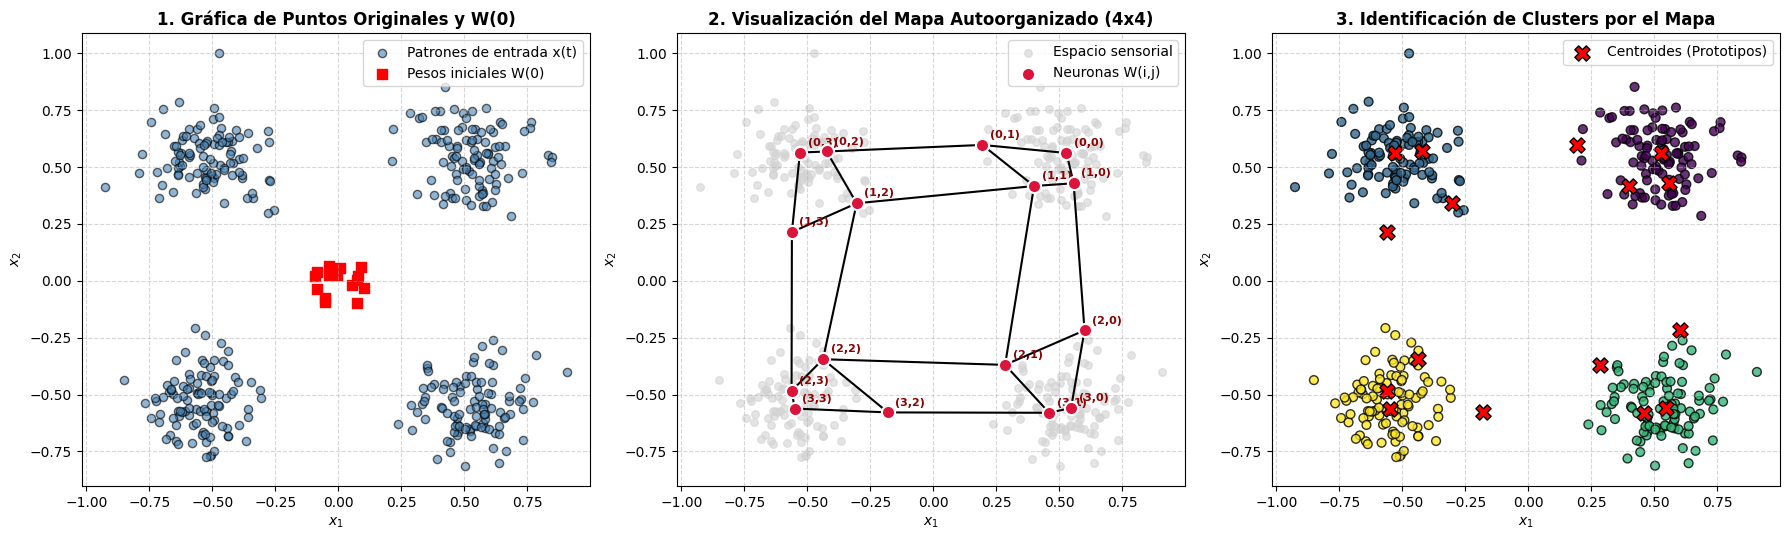


--- MATRIZ DE FRECUENCIA DE ACTIVACIÓN DEL MAPA (4x4) ---
(Cantidad de patrones capturados por cada neurona (i,j)):
[[57  6 29 59]
 [26 11  8  4]
 [ 9  6 16 34]
 [48 37  5 45]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 1. PREPARACIÓN Y GENERACIÓN DEL CONJUNTO DE DATOS

np.random.seed(42)

# Generación de 4 grupos (clusters) en el plano 2D
n_puntos_por_cluster = 100
centros = [[-2.0, -2.0], [-2.0, 2.0], [2.0, -2.0], [2.0, 2.0]]
desviacion = 0.45

datos_lista = []
etiquetas_reales = [] # Solo para validación visual posterior (no se usan en el entrenamiento)

for idx, centro in enumerate(centros):
    cluster = np.random.normal(loc=centro, scale=desviacion, size=(n_puntos_por_cluster, 2))
    datos_lista.append(cluster)
    etiquetas_reales.extend([idx] * n_puntos_por_cluster)

X = np.vstack(datos_lista)
# Escalado al rango [-1, 1] para normalizar el espacio sensorial
X = X / np.max(np.abs(X))
num_patrones, m = X.shape  # m = 2 variables de entrada (x1, x2)


# 2. DEFINICIÓN DEL MAPA DE KOHONEN Y PARÁMETROS (Según PDF de clase)

nx, ny = 4, 4  # Reticulado bidimensional de 4x4 neuronas (16 U.P.s)

# Paso 1: Inicialización de pesos sinápticos W_ijk con valores aleatorios pequeños
W = np.random.uniform(-0.1, 0.1, (nx, ny, m))
W_inicial = W.copy() # Guardamos copia para graficar el estado inicial

# Parámetros de la Fase 1: Ordenación Global
t_max_ordenacion = 3500
alfa_0 = 0.6
alfa_f = 0.01
R_0 = 3.0
R_f = 1.0

# Parámetros de la Fase 2: Ajuste Fino
t_max_ajuste = 1500
iteraciones_totales = t_max_ordenacion + t_max_ajuste

# Precalcular coordenadas (i, j) del reticulado para medir distancias |i - g|
coords_i, coords_j = np.meshgrid(np.arange(nx), np.arange(ny), indexing='ij')


# 3. ALGORITMO DE APRENDIZAJE AUTOORGANIZADO (Pasos 2 al 6)

for t in range(iteraciones_totales):
    # Determinar parámetros alfa(t) y R(t) según la fase actual
    if t < t_max_ordenacion:
        # Decrecimiento lineal (Fase de ordenación global)
        alfa_t = alfa_0 + (alfa_f - alfa_0) * (t / t_max_ordenacion)
        R_t = R_0 + (R_f - R_0) * (t / t_max_ordenacion)
    else:
        # Valores constantes pequeños (Fase de ajuste fino)
        alfa_t = 0.01
        R_t = 1.0

    # Paso 2: Presentación de un patrón x(t) elegido al azar del conjunto finito
    idx_azar = np.random.randint(0, num_patrones)
    x_t = X[idx_azar]

    # Paso 3: Cálculo de similitud mediante distancia euclídea al cuadrado d^2(w_ij, x)
    distancias_euclideas_cuad = np.sum((W - x_t) ** 2, axis=2)

    # Paso 4: Determinación de la neurona ganadora g = (g1, g2) con menor distancia
    g1, g2 = np.unravel_index(np.argmin(distancias_euclideas_cuad), (nx, ny))

    # Cálculo de distancia topológica en el mapa: |i - g| = sqrt((i - g1)^2 + (j - g2)^2)
    dist_mapa = np.sqrt((coords_i - g1) ** 2 + (coords_j - g2) ** 2)

    # Función de vecindad tipo escalón (rectangular): h(|i-g|, t) = 1 si |i-g| <= R(t), 0 si no
    h = np.where(dist_mapa <= R_t, 1.0, 0.0)

    # Paso 5: Actualización de pesos de la neurona ganadora y sus vecinas
    # w_ijk(t+1) = w_ijk(t) + alfa(t) * h(|i-g|, t) * (x_k(t) - w_ijk(t))
    W += alfa_t * h[:, :, np.newaxis] * (x_t - W)

print("✅ Entrenamiento del Mapa de Kohonen finalizado con éxito.")


# 4. IDENTIFICACIÓN DE GRUPOS (FASE DE EJECUCIÓN CON PESOS FIJOS)

# Asignamos cada punto x a su neurona ganadora g=(g1, g2) y contamos activaciones
ganadoras_por_punto = np.zeros(num_patrones, dtype=int)
mapa_activaciones = np.zeros((nx, ny), dtype=int)

for idx in range(num_patrones):
    dist_cuad = np.sum((W - X[idx]) ** 2, axis=2)
    g1, g2 = np.unravel_index(np.argmin(dist_cuad), (nx, ny))
    ganadoras_por_punto[idx] = g1 * ny + g2  # ID único de neurona (0 a 15)
    mapa_activaciones[g1, g2] += 1


# 5. GENERACIÓN DE GRÁFICAS Y EVIDENCIAS VISUALES

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# --- Gráfica 1: Puntos Originales y Pesos Iniciales ---
axes[0].scatter(X[:, 0], X[:, 1], c='steelblue', alpha=0.6, edgecolors='k', s=35, label='Patrones de entrada x(t)')
axes[0].scatter(W_inicial[:, :, 0], W_inicial[:, :, 1], c='red', marker='s', s=50, label='Pesos iniciales W(0)')
axes[0].set_title('1. Gráfica de Puntos Originales y W(0)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Gráfica 2: Visualización del Mapa Autoorganizado Desplegado ---
axes[1].scatter(X[:, 0], X[:, 1], c='lightgray', alpha=0.6, s=30, label='Espacio sensorial')
# Dibujar las conexiones del reticulado topológico (filas y columnas de la red)
for i in range(nx):
    axes[1].plot(W[i, :, 0], W[i, :, 1], 'k-', lw=1.5, zorder=3)
for j in range(ny):
    axes[1].plot(W[:, j, 0], W[:, j, 1], 'k-', lw=1.5, zorder=3)

axes[1].scatter(W[:, :, 0], W[:, :, 1], c='crimson', marker='o', s=90, edgecolors='white', lw=1.5, zorder=4, label='Neuronas W(i,j)')
for i in range(nx):
    for j in range(ny):
        axes[1].text(W[i, j, 0]+0.03, W[i, j, 1]+0.03, f'({i},{j})', fontsize=8, fontweight='bold', color='darkred')

axes[1].set_title('2. Visualización del Mapa Autoorganizado (4x4)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

# --- Gráfica 3: Identificación de Grupos (Clustering por Cuantificación) ---
# Agrupamos visualmente según el cuadrante del mapa (4 macro-clusters de 2x2 neuronas)
cluster_asignado = []
for idx in range(num_patrones):
    dist_cuad = np.sum((W - X[idx]) ** 2, axis=2)
    g1, g2 = np.unravel_index(np.argmin(dist_cuad), (nx, ny))
    # Dividimos el mapa 4x4 en 4 cuadrantes topológicos: (0..1, 0..1), (0..1, 2..3), etc.
    cuadrante = (0 if g1 < 2 else 2) + (0 if g2 < 2 else 1)
    cluster_asignado.append(cuadrante)

scatter = axes[2].scatter(X[:, 0], X[:, 1], c=cluster_asignado, cmap='viridis', alpha=0.8, edgecolors='k', s=40)
axes[2].scatter(W[:, :, 0], W[:, :, 1], c='red', marker='X', s=120, edgecolors='black', label='Centroides (Prototipos)')
axes[2].set_title('3. Identificación de Clusters por el Mapa', fontsize=12, fontweight='bold')
axes[2].set_xlabel('$x_1$')
axes[2].set_ylabel('$x_2$')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# --- Reporte numérico en consola ---
print("\n--- MATRIZ DE FRECUENCIA DE ACTIVACIÓN DEL MAPA (4x4) ---")
print("(Cantidad de patrones capturados por cada neurona (i,j)):")
print(mapa_activaciones)

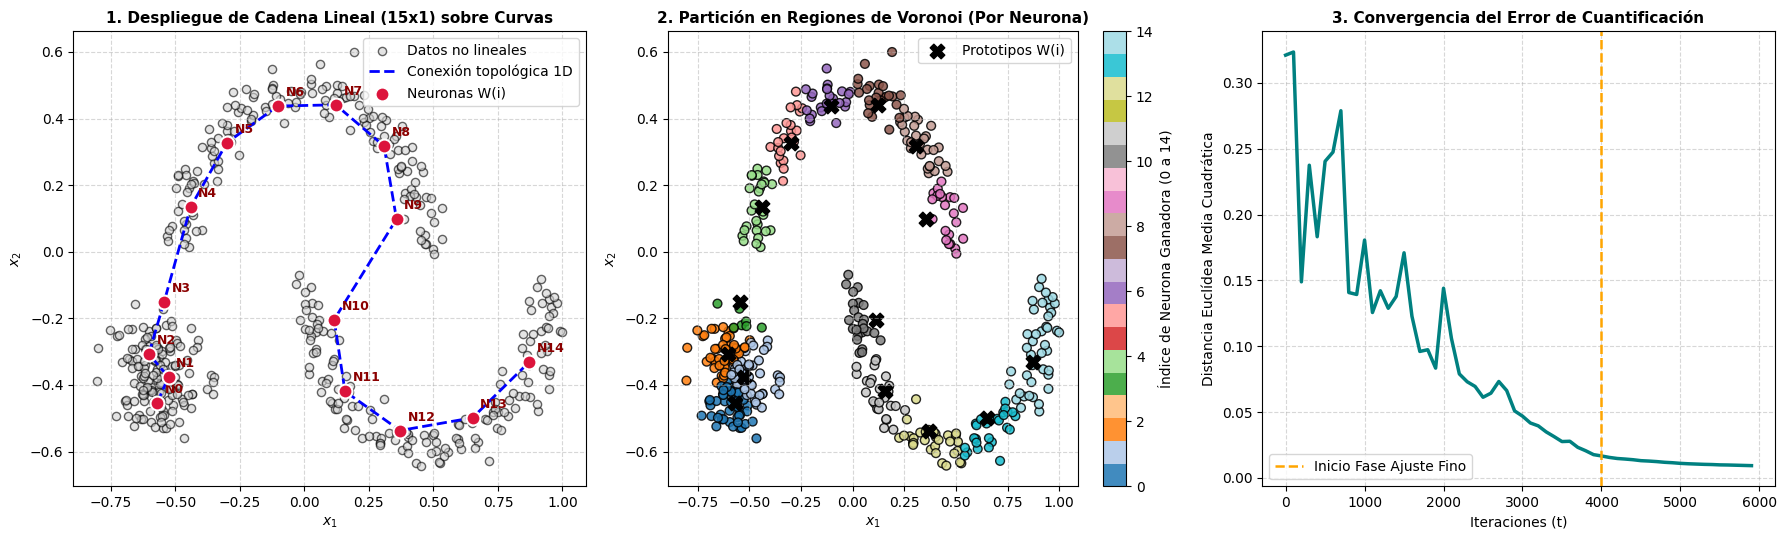

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


# 1. GENERACIÓN DE DATOS NO LINEALES (2 Medias Lunas + 1 Cluster Circular)

np.random.seed(42)
n_por_grupo = 150

# Grupo 1: Arco / Media luna superior
angulos_1 = np.linspace(0, np.pi, n_por_grupo)
x1_g1 = np.cos(angulos_1) + np.random.normal(0, 0.08, n_por_grupo)
x2_g1 = np.sin(angulos_1) + np.random.normal(0, 0.08, n_por_grupo)
grupo_1 = np.column_stack((x1_g1, x2_g1))

# Grupo 2: Arco / Media luna inferior desplazada
angulos_2 = np.linspace(0, np.pi, n_por_grupo)
x1_g2 = 1.0 - np.cos(angulos_2) + np.random.normal(0, 0.08, n_por_grupo)
x2_g2 = -0.2 - np.sin(angulos_2) + np.random.normal(0, 0.08, n_por_grupo)
grupo_2 = np.column_stack((x1_g2, x2_g2))

# Grupo 3: Cluster circular aislado a la izquierda
grupo_3 = np.random.normal(loc=[-1.2, -0.8], scale=0.18, size=(n_por_grupo, 2))

# Unir todos los patrones y normalizar al rango [-1, 1]
X = np.vstack([grupo_1, grupo_2, grupo_3])
X = X / np.max(np.abs(X))
num_patrones, m = X.shape


# 2. DEFINICIÓN DEL MAPA (Cadena Lineal 1D y Vecindad Gaussiana)

# Usamos una cadena lineal de 15 neuronas (nx=15, ny=1) como indica la teoría
nx, ny = 15, 1

# Paso 1: Inicialización de pesos aleatorios pequeños en [-0.1, 0.1]
W = np.random.uniform(-0.1, 0.1, (nx, ny, m))
W_inicial = W.copy()

# Parámetros de aprendizaje (Ordenación Global + Ajuste Fino)
t_max_ordenacion = 4000
t_max_ajuste = 2000
iteraciones_totales = t_max_ordenacion + t_max_ajuste

alfa_0, alfa_f = 0.7, 0.01
R_0, R_f = 6.0, 0.8  # Radio inicial amplio para ordenar las 15 neuronas en fila

coords_i, coords_j = np.meshgrid(np.arange(nx), np.arange(ny), indexing='ij')
historial_error = []


# 3. ENTRENAMIENTO DEL MAPA DE KOHONEN

for t in range(iteraciones_totales):
    if t < t_max_ordenacion:
        # Decrecimiento lineal en fase de ordenación global
        alfa_t = alfa_0 + (alfa_f - alfa_0) * (t / t_max_ordenacion)
        R_t = R_0 + (R_f - R_0) * (t / t_max_ordenacion)
    else:
        # Fase de ajuste fino
        alfa_t = 0.01
        R_t = 0.5

    # Paso 2: Selección aleatoria de un patrón x(t)
    x_t = X[np.random.randint(0, num_patrones)]

    # Paso 3 y 4: Distancia euclídea y neurona ganadora g = (g1, g2)
    dist_euclidea_cuad = np.sum((W - x_t) ** 2, axis=2)
    g1, g2 = np.unravel_index(np.argmin(dist_euclidea_cuad), (nx, ny))

    # Distancia topológica en el mapa |i - g|
    dist_mapa_cuad = (coords_i - g1) ** 2 + (coords_j - g2) ** 2

    # Función de vecindad Gaussiana (continua y derivable según el PDF)
    h = np.exp(-dist_mapa_cuad / (2 * (R_t ** 2)))

    # Paso 5: Regla de actualización de Kohonen
    W += alfa_t * h[:, :, np.newaxis] * (x_t - W)

    # Registrar error de cuantificación cada 100 iteraciones
    if t % 100 == 0:
        err = np.mean([np.min(np.sum((W - p) ** 2, axis=2)) for p in X])
        historial_error.append(err)


# 4. ASIGNACIÓN DE CLUSTERS Y VISUALIZACIÓN

# Clasificamos cada patrón según el segmento de la cadena neuronal que lo activa
# (Neuronas 0-2: Cluster circular, Neuronas 3-8: Luna inferior, Neuronas 9-14: Luna superior)
neurona_ganadora = np.zeros(num_patrones, dtype=int)
for idx in range(num_patrones):
    dist_cuad = np.sum((W - X[idx]) ** 2, axis=2)
    g1, _ = np.unravel_index(np.argmin(dist_cuad), (nx, ny))
    neurona_ganadora[idx] = g1

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# --- Gráfica 1: Despliegue de la Cadena Lineal sobre los Datos Curvos ---
axes[0].scatter(X[:, 0], X[:, 1], c='lightgray', s=35, edgecolors='k', alpha=0.6, label='Datos no lineales')
axes[0].plot(W[:, 0, 0], W[:, 0, 1], 'b--', lw=2, label='Conexión topológica 1D', zorder=3)
axes[0].scatter(W[:, 0, 0], W[:, 0, 1], c='crimson', s=100, edgecolors='white', lw=1.5, zorder=4, label='Neuronas W(i)')
for i in range(nx):
    axes[0].text(W[i, 0, 0]+0.03, W[i, 0, 1]+0.03, f'N{i}', fontsize=9, fontweight='bold', color='darkred')
axes[0].set_title('1. Despliegue de Cadena Lineal (15x1) sobre Curvas', fontsize=11, fontweight='bold')
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Gráfica 2: Mapa de Colores por Neurona Ganadora (Dominios de Voronoi) ---
scatter = axes[1].scatter(X[:, 0], X[:, 1], c=neurona_ganadora, cmap='tab20', s=40, edgecolors='k', alpha=0.85)
axes[1].scatter(W[:, 0, 0], W[:, 0, 1], c='black', marker='X', s=110, label='Prototipos W(i)')
axes[1].set_title('2. Partición en Regiones de Voronoi (Por Neurona)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
plt.colorbar(scatter, ax=axes[1], label='Índice de Neurona Ganadora (0 a 14)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# --- Gráfica 3: Curva de Convergencia (Error de Cuantificación) ---
iter_eje = np.arange(0, iteraciones_totales, 100)
axes[2].plot(iter_eje, historial_error, color='teal', lw=2.5)
axes[2].axvline(x=t_max_ordenacion, color='orange', linestyle='--', lw=1.8, label='Inicio Fase Ajuste Fino')
axes[2].set_title('3. Convergencia del Error de Cuantificación', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Iteraciones (t)')
axes[2].set_ylabel('Distancia Euclídea Media Cuadrática')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()